# 04 · 1D CNN
Version A: raw beat only. Version B: raw beat + 8 RR features. Class-weighted, model selected by validation macro-F1. Test set not used here.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import sys
sys.path.append('/content/drive/MyDrive/ECG_Arrhythmia_Classification/src')

import json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, Model
from sklearn.metrics import f1_score, confusion_matrix

from config import *
print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices('GPU'))

Mounted at /content/drive
TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
%%writefile /content/drive/MyDrive/ECG_Arrhythmia_Classification/src/eval_utils.py
import numpy as np
from sklearn.metrics import f1_score, precision_score, recall_score

def evaluate(y_true, y_pred, cls):
    """Same metrics for every model: macro-F1, abnormal precision/recall, recall per subtype."""
    return {
        'macro_f1':     round(float(f1_score(y_true, y_pred, average='macro')), 4),
        'ab_precision': round(float(precision_score(y_true, y_pred, zero_division=0)), 4),
        'ab_recall':    round(float(recall_score(y_true, y_pred)), 4),
        **{f'recall_{c}': round(float((y_pred[cls == c] == 1).mean()), 4) for c in 'SVF'},
    }

Writing /content/drive/MyDrive/ECG_Arrhythmia_Classification/src/eval_utils.py


In [3]:
from eval_utils import evaluate

def load(name):
    d = np.load(f'{PROC_DIR}/{name}.npz')
    return {k: d[k] for k in d.files}

train, val = load('train'), load('val')          # test stays closed 🔒

Xtr, Xva = train['X'][..., None], val['X'][..., None]     # (n, 252) → (n, 252, 1)
ytr, yva = train['y'].astype('float32'), val['y'].astype('float32')

rr_mean, rr_std = train['rr'].mean(axis=0), train['rr'].std(axis=0)   # TRAIN only
RRtr = ((train['rr'] - rr_mean) / rr_std).astype('float32')
RRva = ((val['rr']   - rr_mean) / rr_std).astype('float32')
with open(f'{MODEL_DIR}/rr_scaler.json', 'w') as f:
    json.dump({'mean': rr_mean.tolist(), 'std': rr_std.tolist()}, f, indent=2)

with open(f'{RES_DIR}/class_weights.json') as f:
    class_weight = {int(k): v for k, v in json.load(f).items()}

print("Beats:", Xtr.shape, Xva.shape, "| RR:", RRtr.shape)
print("Scaled RR (train) mean:", RRtr.mean(0).round(2))
print("Scaled RR (train) std :", RRtr.std(0).round(2))
print("Class weights:", class_weight)

Beats: (39015, 252, 1) (11954, 252, 1) | RR: (39015, 8)
Scaled RR (train) mean: [-0. -0.  0. -0. -0.  0.  0.  0.]
Scaled RR (train) std : [1. 1. 1. 1. 1. 1. 1. 1.]
Class weights: {0: 0.5668807392769964, 1: 4.237996958505323}


In [4]:
def build_cnn(use_rr):
    beat = layers.Input(shape=(BEFORE + AFTER, 1), name='beat')
    x = layers.Conv1D(16, 7, padding='same', activation='relu')(beat)
    x = layers.MaxPooling1D(2)(x)
    x = layers.Conv1D(32, 5, padding='same', activation='relu')(x)
    x = layers.MaxPooling1D(2)(x)
    x = layers.Conv1D(64, 3, padding='same', activation='relu')(x)
    x = layers.GlobalAveragePooling1D()(x)

    if use_rr:
        rr = layers.Input(shape=(len(RR_COLS),), name='rr')
        x = layers.Concatenate()([x, rr])           # learned shape + timing, side by side
        inputs = [beat, rr]
    else:
        inputs = beat

    x = layers.Dropout(0.3)(x)
    x = layers.Dense(32, activation='relu')(x)
    out = layers.Dense(1, activation='sigmoid')(x)

    model = Model(inputs, out, name='cnn_B_beat_rr' if use_rr else 'cnn_A_beat')
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss='binary_crossentropy')
    return model

build_cnn(use_rr=True).summary()

Model: "cnn_B_beat_rr"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ beat (InputLayer)   │ (None, 252, 1)    │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d (Conv1D)     │ (None, 252, 16)   │        128 │ beat[0][0]        │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d       │ (None, 126, 16)   │          0 │ conv1d[0][0]      │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_1 (Conv1D)   │ (None, 126, 32)   │      2,592 │ max_pooling1d[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_1     │ (None, 63, 32)    │          0 │ conv1d_1[0][0]    │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_2 (Conv1D)   │ (None, 63, 64)    │      6,208 │ max_pooling1d_1[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 64)        │          0 │ conv1d_2[0][0]    │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rr (InputLayer)     │ (None, 8)         │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 72)        │          0 │ global_average_p… │
│ (Concatenate)       │                   │            │ rr[0][0]          │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 72)        │          0 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 32)        │      2,336 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 1)         │         33 │ dense[0][0]       │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 11,297 (44.13 KB)

 Trainable params: 11,297 (44.13 KB)

 Non-trainable params: 0 (0.00 B)

In [5]:
class MacroF1Checkpoint(tf.keras.callbacks.Callback):
    """After each epoch: compute val macro-F1, save the best model, stop if no improvement."""
    def __init__(self, x_val, y_val, path, patience=8):
        super().__init__()
        self.x_val, self.y_val, self.path, self.patience = x_val, y_val, path, patience
        self.scores, self.best, self.best_epoch, self.wait = [], -1, 0, 0

    def on_epoch_end(self, epoch, logs=None):
        prob = self.model.predict(self.x_val, batch_size=2048, verbose=0).ravel()
        f1 = f1_score(self.y_val, (prob >= 0.5).astype(int), average='macro')
        self.scores.append(f1)
        if f1 > self.best:
            self.best, self.best_epoch, self.wait = f1, epoch + 1, 0
            self.model.save(self.path)
        else:
            self.wait += 1
            if self.wait >= self.patience:
                self.model.stop_training = True
        print(f"  epoch {epoch + 1:2d} | loss {logs['loss']:.4f} | val_loss {logs['val_loss']:.4f} "
              f"| val macro-F1 {f1:.4f}" + ("  ⭐" if self.wait == 0 else ""))

def train_cnn(use_rr, seed=SEED, epochs=40, batch_size=256):
    tf.keras.utils.set_random_seed(seed)             # same starting weights every run
    name = ('cnn_B_beat_rr' if use_rr else 'cnn_A_beat') + f'_seed{seed}'
    x_tr = [Xtr, RRtr] if use_rr else Xtr
    x_va = [Xva, RRva] if use_rr else Xva

    model = build_cnn(use_rr)
    ckpt = MacroF1Checkpoint(x_va, yva.astype(int), f'{MODEL_DIR}/{name}.keras')
    print(f"\n=== Training {name} ===")
    t0 = time.time()
    hist = model.fit(x_tr, ytr, validation_data=(x_va, yva), epochs=epochs,
                     batch_size=batch_size, class_weight=class_weight,
                     callbacks=[ckpt], verbose=0)
    print(f"→ best val macro-F1 {ckpt.best:.4f} at epoch {ckpt.best_epoch} | {time.time() - t0:.0f} s")
    return name, hist.history, ckpt


=== Training cnn_A_beat_seed42 ===
  epoch  1 | loss 0.5633 | val_loss 0.2685 | val macro-F1 0.7344  ⭐
  epoch  2 | loss 0.4130 | val_loss 0.2526 | val macro-F1 0.7403  ⭐
  epoch  3 | loss 0.3407 | val_loss 0.2611 | val macro-F1 0.7447  ⭐
  epoch  4 | loss 0.2989 | val_loss 0.2809 | val macro-F1 0.7746  ⭐
  epoch  5 | loss 0.2735 | val_loss 0.2465 | val macro-F1 0.7659
  epoch  6 | loss 0.2525 | val_loss 0.2454 | val macro-F1 0.7714
  epoch  7 | loss 0.2378 | val_loss 0.2212 | val macro-F1 0.7768  ⭐
  epoch  8 | loss 0.2261 | val_loss 0.1989 | val macro-F1 0.7768  ⭐
  epoch  9 | loss 0.2183 | val_loss 0.1723 | val macro-F1 0.7777  ⭐
  epoch 10 | loss 0.2052 | val_loss 0.1855 | val macro-F1 0.7636
  epoch 11 | loss 0.2034 | val_loss 0.1767 | val macro-F1 0.7633
  epoch 12 | loss 0.1909 | val_loss 0.1783 | val macro-F1 0.7626
  epoch 13 | loss 0.1886 | val_loss 0.1727 | val macro-F1 0.7643
  epoch 14 | loss 0.1849 | val_loss 0.1724 | val macro-F1 0.7595
  epoch 15 | loss 0.1833 | val_lo

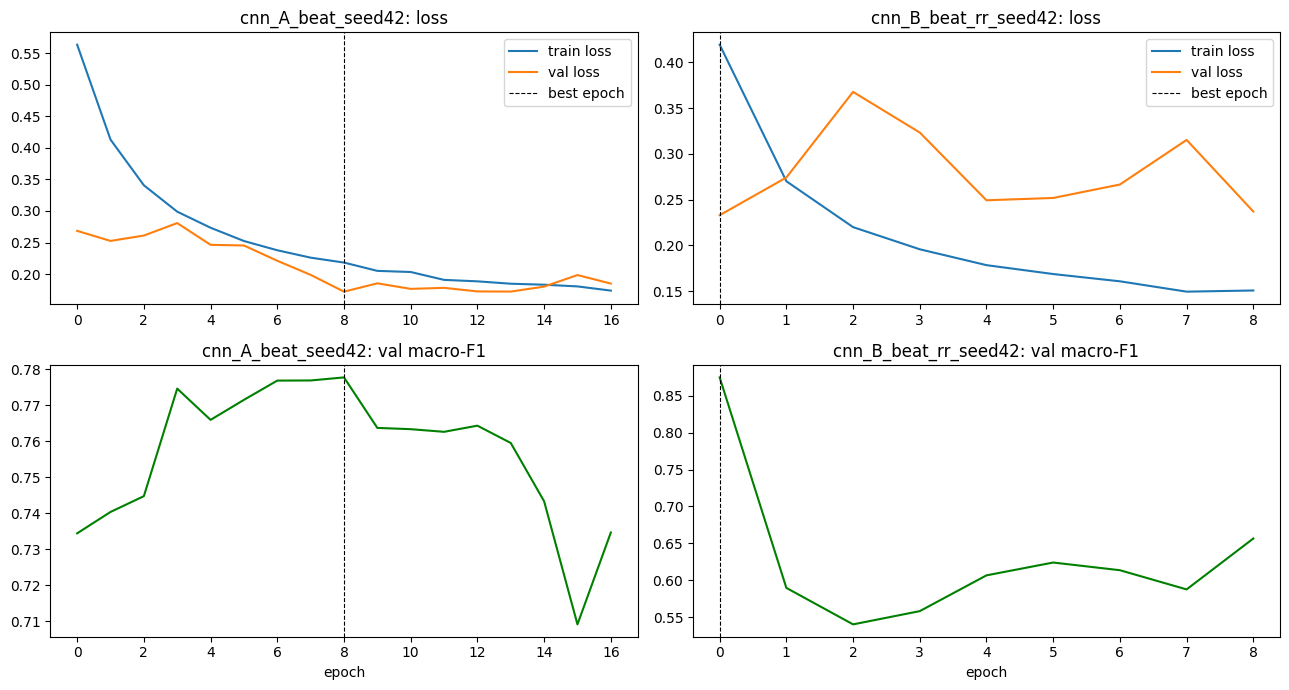

In [6]:
runs = {}
for use_rr in [False, True]:
    name, hist, ckpt = train_cnn(use_rr)
    runs[name] = (hist, ckpt)

fig, axes = plt.subplots(2, 2, figsize=(13, 7))
for col, (name, (hist, ckpt)) in enumerate(runs.items()):
    best = ckpt.best_epoch - 1
    ax = axes[0, col]
    ax.plot(hist['loss'], label='train loss')
    ax.plot(hist['val_loss'], label='val loss')
    ax.axvline(best, color='k', ls='--', lw=0.8, label='best epoch')
    ax.set_title(f'{name}: loss'); ax.legend()
    ax = axes[1, col]
    ax.plot(ckpt.scores, color='green')
    ax.axvline(best, color='k', ls='--', lw=0.8)
    ax.set_title(f'{name}: val macro-F1'); ax.set_xlabel('epoch')
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/09_cnn_learning_curves.png', dpi=150, bbox_inches='tight')
plt.show()

In [7]:
rows = []
for name in runs:
    model = tf.keras.models.load_model(f'{MODEL_DIR}/{name}.keras')    # best epoch
    x_va = [Xva, RRva] if 'cnn_B' in name else Xva
    p = (model.predict(x_va, batch_size=2048, verbose=0).ravel() >= 0.5).astype(int)
    rows.append({'model': name, **evaluate(val['y'], p, val['cls'])})
    print(name, "confusion matrix [[TN FP] [FN TP]]:\n", confusion_matrix(val['y'], p))

rf = pd.read_csv(f'{RES_DIR}/rf_ablation_val.csv').rename(columns={'features': 'model'})
rf['model'] = 'RF: ' + rf['model']
comparison = pd.concat([rf, pd.DataFrame(rows)]).set_index('model')
comparison.to_csv(f'{RES_DIR}/cnn_vs_rf_val.csv')
print(comparison)

cnn_A_beat_seed42 confusion matrix [[TN FP] [FN TP]]:
 [[11363    49]
 [  306   236]]
cnn_B_beat_rr_seed42 confusion matrix [[TN FP] [FN TP]]:
 [[11312   100]
 [  148   394]]
                      macro_f1  ab_precision  ab_recall  recall_S  recall_V  \
model                                                                         
RF: RR only (timing)    0.9001        0.8966     0.7362    0.8282    0.7081   
RF: Shape only          0.5336        0.1092     0.4520    0.1233    0.7181   
RF: RR + shape          0.9367        0.9930     0.7878    0.7885    0.8322   
cnn_A_beat_seed42       0.7777        0.8281     0.4354    0.1013    0.7013   
cnn_B_beat_rr_seed42    0.8749        0.7976     0.7269    0.4890    0.9463   

                      recall_F  
model                           
RF: RR only (timing)    0.0000  
RF: Shape only          0.1765  
RF: RR + shape          0.0000  
cnn_A_beat_seed42       0.2353  
cnn_B_beat_rr_seed42    0.0588  


In [8]:
seed_rows = []
for seed in [1, 2]:
    for use_rr in [False, True]:
        name, hist, ckpt = train_cnn(use_rr, seed=seed)
        model = tf.keras.models.load_model(f'{MODEL_DIR}/{name}.keras')
        x_va = [Xva, RRva] if use_rr else Xva
        p = (model.predict(x_va, batch_size=2048, verbose=0).ravel() >= 0.5).astype(int)
        seed_rows.append({'model': name, **evaluate(val['y'], p, val['cls'])})

all_runs = pd.concat([pd.DataFrame(rows), pd.DataFrame(seed_rows)])
all_runs['variant'] = all_runs['model'].str.extract(r'(cnn_[AB])')
all_runs.to_csv(f'{RES_DIR}/cnn_seeds_val.csv', index=False)
print(all_runs.groupby('variant')[['macro_f1', 'ab_precision', 'ab_recall',
                                   'recall_S', 'recall_V']].agg(['mean', 'std']).round(3))


=== Training cnn_A_beat_seed1 ===


  epoch  1 | loss 0.5681 | val_loss 0.3059 | val macro-F1 0.7208  ⭐
  epoch  2 | loss 0.4047 | val_loss 0.3140 | val macro-F1 0.6500
  epoch  3 | loss 0.3363 | val_loss 0.2670 | val macro-F1 0.6919
  epoch  4 | loss 0.2961 | val_loss 0.2297 | val macro-F1 0.7033
  epoch  5 | loss 0.2671 | val_loss 0.1948 | val macro-F1 0.7059
  epoch  6 | loss 0.2500 | val_loss 0.2164 | val macro-F1 0.7212  ⭐
  epoch  7 | loss 0.2339 | val_loss 0.1923 | val macro-F1 0.7284  ⭐
  epoch  8 | loss 0.2246 | val_loss 0.1847 | val macro-F1 0.7151
  epoch  9 | loss 0.2130 | val_loss 0.1769 | val macro-F1 0.7168
  epoch 10 | loss 0.2072 | val_loss 0.1675 | val macro-F1 0.7189
  epoch 11 | loss 0.2058 | val_loss 0.1933 | val macro-F1 0.7081
  epoch 12 | loss 0.2003 | val_loss 0.2044 | val macro-F1 0.6889
  epoch 13 | loss 0.1927 | val_loss 0.1939 | val macro-F1 0.7096
  epoch 14 | loss 0.1901 | val_loss 0.1530 | val macro-F1 0.7169
  epoch 15 | loss 0.1853 | val_loss 0.1669 | val macro-F1 0.7273
→ best val macro

In [9]:
!pip install -q wfdb
import wfdb
from collections import Counter

def original_symbols(records, rpeaks, rec_ids):
    """Look up the original MIT-BIH label (N, L, R, A, V, ...) for each saved beat."""
    sym = np.empty(len(rpeaks), dtype='<U1')
    for r in records:
        ann = wfdb.rdann(f'{RAW_DIR}/{r}', 'atr')
        lookup = dict(zip(ann.sample, ann.symbol))
        idx = np.where(rec_ids == r)[0]
        sym[idx] = [lookup[p] for p in rpeaks[idx]]
    return sym

train_sym = original_symbols(TRAIN_RECORDS, train['rpeak'], train['record'])
val_sym   = original_symbols(VAL_RECORDS,   val['rpeak'],   val['record'])
print("Train original labels:", dict(Counter(train_sym)))
print("Val original labels:  ", dict(Counter(val_sym)))

for name in ['cnn_A_beat_seed42', 'cnn_B_beat_rr_seed42', 'cnn_B_beat_rr_seed1']:
    model = tf.keras.models.load_model(f'{MODEL_DIR}/{name}.keras')
    x_va = [Xva, RRva] if 'cnn_B' in name else Xva
    p = (model.predict(x_va, batch_size=2048, verbose=0).ravel() >= 0.5).astype(int)
    fp = (p == 1) & (val['y'] == 0)        # false alarms
    fn = (p == 0) & (val['y'] == 1)        # missed abnormal beats
    print(f"\n===== {name} =====")
    print(f"False alarms: {fp.sum()}  |  Missed: {fn.sum()}")
    print("False alarms by patient × original label:")
    print(pd.crosstab(val['record'][fp], val_sym[fp]))
    print("Missed beats by patient × class:")
    print(pd.crosstab(val['record'][fn], val['cls'][fn]))

Train original labels: {np.str_('N'): 30353, np.str_('A'): 611, np.str_('V'): 3385, np.str_('F'): 397, np.str_('j'): 11, np.str_('L'): 3947, np.str_('J'): 3, np.str_('a'): 100, np.str_('R'): 85, np.str_('E'): 105, np.str_('S'): 2, np.str_('e'): 16}
Val original labels:   {np.str_('R'): 3693, np.str_('V'): 298, np.str_('A'): 198, np.str_('J'): 29, np.str_('F'): 17, np.str_('j'): 5, np.str_('N'): 7714}

===== cnn_A_beat_seed42 =====
False alarms: 49  |  Missed: 306
False alarms by patient × original label:
col_0   N  R
row_0       
118     0  9
215    38  0
220     2  0
Missed beats by patient × class:
col_0   F   S   V
row_0            
118     0  95  13
124     3  31   3
205    10   3   0
215     0   3  73
220     0  72   0



===== cnn_B_beat_rr_seed42 =====
False alarms: 100  |  Missed: 148
False alarms by patient × original label:
col_0   N  R
row_0       
118     0  3
215    97  0
Missed beats by patient × class:
col_0   F   S   V
row_0            
118     0  25   1
124     4  30  11
205    11   2   3
215     1   0   1
220     0  59   0

===== cnn_B_beat_rr_seed1 =====
False alarms: 159  |  Missed: 161
False alarms by patient × original label:
col_0    N  R
row_0        
118      0  3
205     16  0
215    138  0
220      2  0
Missed beats by patient × class:
col_0   F   S   V
row_0            
118     0  25   6
124     5  31  24
205    10   0   1
215     1   0  49
220     0   9   0


Label of the PREVIOUS beat, for false alarms: {np.str_('N'): 138}
Label of the PREVIOUS beat, for correct N:     {np.str_('N'): 2911, np.str_('V'): 141, np.str_('A'): 3}

Median RR features:
                false alarms  correct N
pre_rr                 0.510      0.536
post_rr                0.504      0.533
local_rr               0.540      0.538
long_rr                0.536      0.533
rel_pre_local          0.945      1.002
rel_post_local         0.934      0.993
rel_pre_long           0.953      1.005
rel_post_long          0.948      1.000


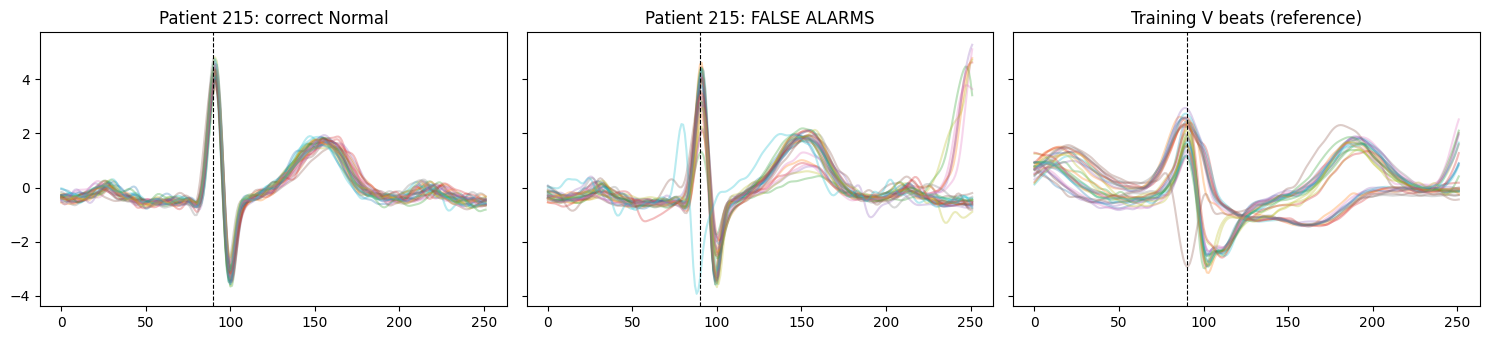

In [10]:
model = tf.keras.models.load_model(f'{MODEL_DIR}/cnn_B_beat_rr_seed1.keras')
p = (model.predict([Xva, RRva], batch_size=2048, verbose=0).ravel() >= 0.5).astype(int)

in215 = val['record'] == 215
fp215 = in215 & (p == 1) & (val['y'] == 0)        # normal beats wrongly flagged
ok215 = in215 & (p == 0) & (val['y'] == 0)        # normal beats correctly kept

# What came just BEFORE each beat? (beats are stored in time order per patient)
prev_sym = np.roll(val_sym, 1)
print("Label of the PREVIOUS beat, for false alarms:", dict(Counter(prev_sym[fp215])))
print("Label of the PREVIOUS beat, for correct N:    ", dict(Counter(prev_sym[ok215])))

df215 = pd.DataFrame(val['rr'], columns=RR_COLS)
print("\nMedian RR features:")
print(pd.DataFrame({'false alarms': df215[fp215].median(), 'correct N': df215[ok215].median()}).round(3))

fig, axes = plt.subplots(1, 3, figsize=(15, 3.5), sharey=True)
panels = [(np.where(ok215)[0][:30], 'Patient 215: correct Normal'),
          (np.where(fp215)[0][:30], 'Patient 215: FALSE ALARMS'),
          (np.where(train['cls'] == 'V')[0][:30], 'Training V beats (reference)')]
for ax, (idx, title) in zip(axes, panels):
    data = train['X'] if 'Training' in title else val['X']
    for i in idx:
        ax.plot(data[i], alpha=0.3)
    ax.axvline(BEFORE, color='k', ls='--', lw=0.8)
    ax.set_title(title)
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/10_patient215_false_alarms.png', dpi=150, bbox_inches='tight')
plt.show()

## Key findings (validation only, test not used)

**Setup:** 1D CNN, 11,297 parameters. Version A = raw beat only. Version B = raw beat + 8 RR features (scaled with train mean/std). Class weights, best epoch chosen by val macro-F1, 3 seeds (42, 1, 2).

**Results (mean ± std over 3 seeds):**

| Model | Macro-F1 | Precision | Recall | S recall | V recall |
|---|---|---|---|---|---|
| RF shape only | 0.534 | 0.11 | 0.45 | 0.12 | 0.72 |
| CNN A (raw beat) | 0.742 ± 0.031 | 0.85 | 0.36 | 0.09 | 0.58 |
| RF RR + shape | 0.937 | 0.99 | 0.79 | 0.79 | 0.83 |
| CNN B (beat + RR) | 0.848 ± 0.026 | 0.81 | 0.65 | 0.44 ± 0.31 | 0.84 |

- **Learned shape > handcrafted shape:** CNN A 0.742 vs RF shape-only 0.534 (precision 0.85 vs 0.11).
- **CNN B did not beat the full RF** (0.848 vs 0.937), but had high V recall (seed 42: 0.946 vs RF 0.832).
- **CNN B is unstable:** 2 of 3 seeds peaked at epoch 1, then val macro-F1 collapsed while train loss kept falling.
- **Receptive field** of the last conv layer is only ~72 ms, shorter than a wide V QRS.

**Error analysis:**
- RBBB hypothesis **rejected:** val has 3,693 `R` beats (train only 85), but only 3–9 were false alarms.
- **False alarms come from one patient (215):** 78–97% of all false alarms, all normal beats following a normal beat.
- These beats are only slightly early (rel_pre_long 0.953 vs 1.005), and many show a **large upswing at the end of the window** → likely the **next beat entering the window** at 215's fast heart rate (~113 bpm).
- **Working explanation (not proven):** shortcut learning, "bump at the end of the window = abnormal".
- **Errors are patient-clustered:** e.g. patient 220's S beats missed 72 / 59 / 9 times across models → the real sample size is patients, not beats.

**Decision:** no further tuning. All 6 CNN checkpoints + the RF go to Phase 6 unchanged.